# P1 and P2 response time: regression discontinuity design (RDD)

## P1: shift changeover RDD

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "opd_paths.py").exists())   # repo root, where the shared helpers live
sys.path.insert(0, str(REPO))
from opd_paths import DATA   # finds files by name wherever they live in Box (see opd_paths.py)

# Manpower July 2024 unit status log, matched to CAD events (1-29 Jul 2024, 18-19 Jul dropped)
manpower = pd.read_csv(DATA / "Man_Power_2024_July_matched_codes.csv", parse_dates=["Manpower_Record_Time"],
                       dtype={"unit_beat": str}, low_memory=False)

# CAD calls on the same days, one row per event
cad = pd.read_parquet(DATA / "harmonized_calls_2021_2026.parquet",
                      columns=["event_number", "event_time", "priority", "beat", "call_source", "disposition_code"])
cad = cad.drop_duplicates("event_number")
cad["priority"] = pd.to_numeric(cad["priority"], errors="coerce")
day = cad["event_time"].dt.normalize()
cad = cad[day.between("2024-07-01", "2024-07-29") & ~day.isin(pd.to_datetime(["2024-07-18", "2024-07-19"]))]
print(manpower.shape, cad.shape)

(174975, 31) (35219, 6)


In [2]:
# P1 calls from the public (911 and non-911 phone), leaving out calls CAD closed as not needing a police unit
NO_UNIT_NEEDED = ["FA", "AO", "DUP", "CAN", "ROA", "BCAST", "COMM"]   # fire alarm, ambulance ordered, duplicate, cancelled, other agency, broadcasts
p1 = cad[(cad["priority"] == 1)
         & cad["call_source"].isin(["911 CALL", "DEFAULT - PHONE INIT"])
         & ~cad["disposition_code"].isin(NO_UNIT_NEEDED)].copy()

# Response time: minutes from the call coming in (CAD event_time) to the first unit on scene (Manpower)
first_on_scene = (manpower[manpower["code_category"] == "on scene"]
                  .groupby("matched_incident_number")["Manpower_Record_Time"].min())
p1["response_min"] = (p1["event_number"].map(first_on_scene) - p1["event_time"]).dt.total_seconds() / 60
# keep 0 to 24 hours (same rule as beat_response_times and patrol_staffing_and_demand); also drops calls with no on-scene time
p1 = p1[p1["response_min"].between(0, 1440)]

# Patrol Area from the call's beat: Area 1 = beats 1-7, 2 = 8-13, 3 = 14-19, 4 = 20-25, 5 = 26-30, 6 = 31-35
beat_number = pd.to_numeric(p1["beat"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
p1["area"] = pd.cut(beat_number, [0, 7, 13, 19, 25, 30, 35], labels=[1, 2, 3, 4, 5, 6]).astype("Int64")
p1 = p1.dropna(subset=["area"])
print(len(p1), "P1 calls")

3440 P1 calls


In [3]:
# Shift start blocks: 1 hour either side of each watch start; the normal blocks run between them.
# Watch start times: OPD memo "Patrol Staffing and Structure", 1 Jul 2023
GROUPS = {"Areas 1, 3, 5": {"areas": [1, 3, 5], "changes": [6, 14, 21]},
          "Areas 2, 4, 6": {"areas": [2, 4, 6], "changes": [7, 14, 22]}}
CHANGE_HALF = 1   # hours either side of the shift start

def hour_label(h):
    h %= 24
    return "12am" if h == 0 else "12pm" if h == 12 else f"{h % 12}{'am' if h < 12 else 'pm'}"

def blocks(changes):
    """(start, end, kind) in hours, starting at the first shift start block and running 24 hours (end can pass 24)"""
    out = []
    for i, c in enumerate(changes):
        next_c = changes[(i + 1) % len(changes)] + (24 if i == len(changes) - 1 else 0)
        out += [(c - CHANGE_HALF, c + CHANGE_HALF, "shift start"), (c + CHANGE_HALF, next_c - CHANGE_HALF, "normal")]
    return out

# time of day of each P1 call in hours, e.g. 6.5 = 6:30am
p1["hour_of_day"] = p1["event_time"].dt.hour + p1["event_time"].dt.minute / 60 + p1["event_time"].dt.second / 3600

for group, spec in GROUPS.items():
    print(group)
    for start, end, kind in blocks(spec["changes"]):
        print(f"  {kind:13s} {hour_label(start)}-{hour_label(end)}")

Areas 1, 3, 5
  shift start   5am-7am
  normal        7am-1pm
  shift start   1pm-3pm
  normal        3pm-8pm
  shift start   8pm-10pm
  normal        10pm-5am
Areas 2, 4, 6
  shift start   6am-8am
  normal        8am-1pm
  shift start   1pm-3pm
  normal        3pm-9pm
  shift start   9pm-11pm
  normal        11pm-6am


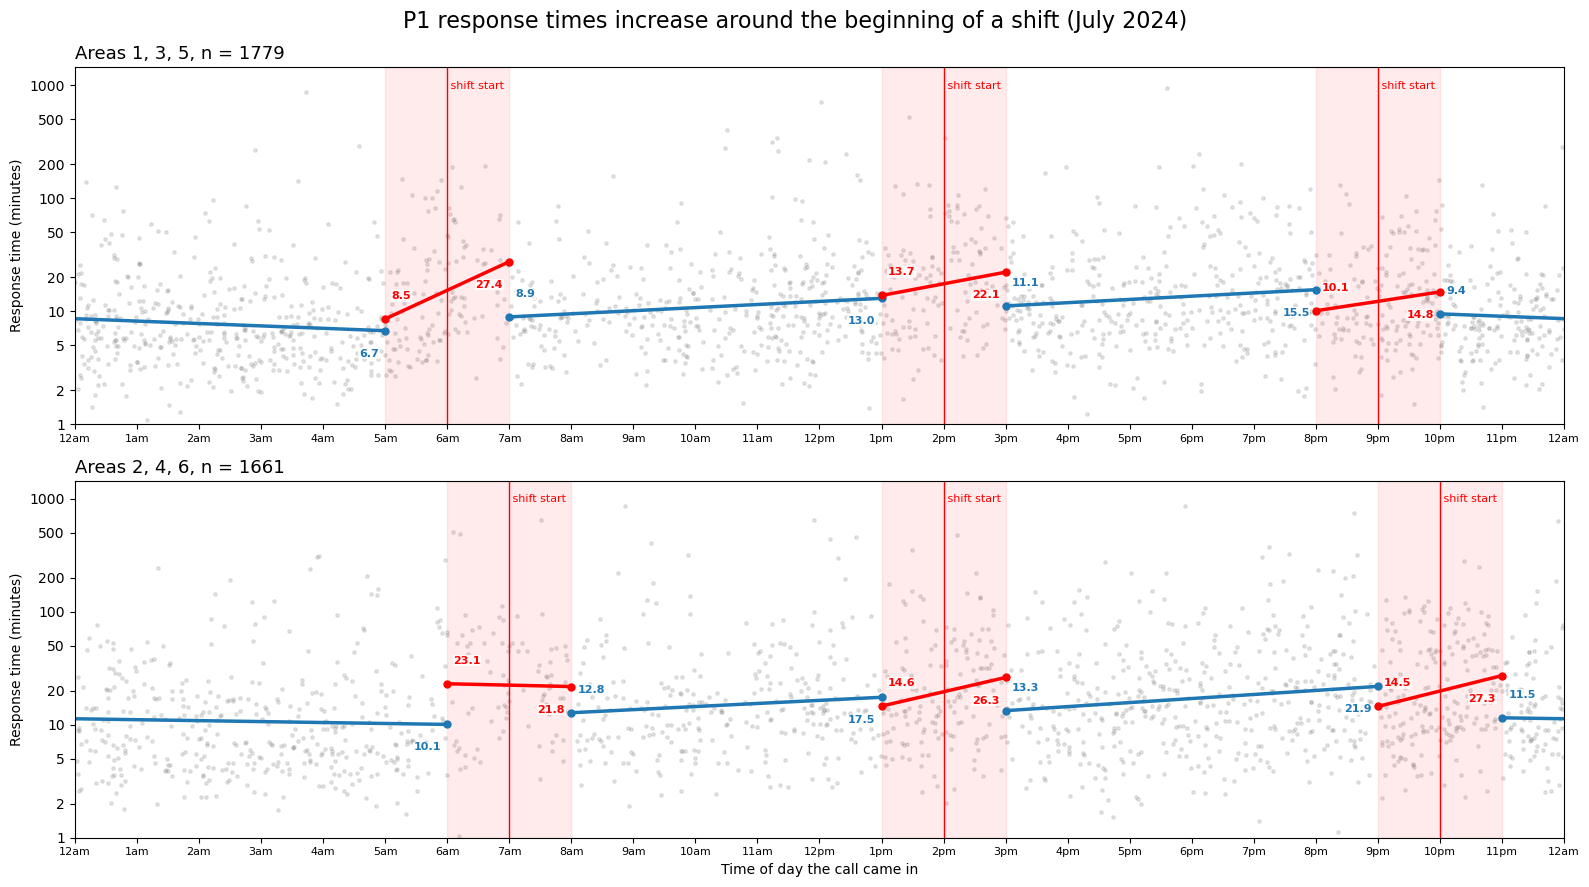

        group       block    hours  calls  line at start (min)  line at end (min)
Areas 1, 3, 5 shift start  5am-7am    124                  8.5               27.4
Areas 1, 3, 5      normal  7am-1pm    402                  8.9               13.0
Areas 1, 3, 5 shift start  1pm-3pm    132                 13.7               22.1
Areas 1, 3, 5      normal  3pm-8pm    365                 11.1               15.5
Areas 1, 3, 5 shift start 8pm-10pm    163                 10.1               14.8
Areas 1, 3, 5      normal 10pm-5am    593                  9.4                6.7
Areas 2, 4, 6 shift start  6am-8am     92                 23.1               21.8
Areas 2, 4, 6      normal  8am-1pm    281                 12.8               17.5
Areas 2, 4, 6 shift start  1pm-3pm    150                 14.6               26.3
Areas 2, 4, 6      normal  3pm-9pm    439                 13.3               21.9
Areas 2, 4, 6 shift start 9pm-11pm    201                 14.5               27.3
Areas 2, 4, 6   

In [4]:
# One line per block, fitted to the log of response time, drawn in minutes on a log y-axis.
# The x-axis runs 12am-12am. The overnight normal block (e.g. 10pm-5am) is fitted as one block and drawn in two pieces.
Y_TICKS = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
BLOCK_COLORS = {"shift start": "red", "normal": "C0"}

def label_ends(ax, start, end, intercept, slope, color):
    """dot and value (minutes) at both ends of a fitted line: start value above right, end value below left"""
    for x_at, dx, y_shift, align in [(start, 0.1, 1.6, "left"), (end, -0.1, 1 / 1.6, "right")]:
        y = np.exp(intercept + slope * x_at)
        x_shown = x_at - 24 if x_at > 24 else x_at                       # past midnight -> early morning on the axis
        ax.plot(x_shown, y, "o", color=color, ms=5, zorder=3)
        ax.text(x_shown + dx, y * y_shift, f"{y:.1f}", color=color, fontsize=8, fontweight="bold", ha=align, va="center",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.5), zorder=4)

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharey=True)
table = []
for ax, (group, spec) in zip(axes, GROUPS.items()):
    calls = p1[p1["area"].isin(spec["areas"])].copy()
    axis_start = spec["changes"][0] - CHANGE_HALF
    calls["x"] = axis_start + (calls["hour_of_day"] - axis_start) % 24     # hours on this axis (past 24 = after midnight)
    ax.scatter(calls["hour_of_day"], calls["response_min"], s=6, alpha=0.2, color="gray")

    for start, end, kind in blocks(spec["changes"]):
        part = calls[(calls["x"] >= start) & (calls["x"] < end)]
        slope, intercept = np.polyfit(part["x"], np.log(part["response_min"]), 1)
        # draw the line; a block that runs past midnight is drawn as two pieces (before and after 12am)
        for a, b in ([(start, 24), (24, end)] if end > 24 else [(start, end)]):
            x = np.array([a, b])
            ax.plot(x % 24 if a >= 24 else x, np.exp(intercept + slope * x), color=BLOCK_COLORS[kind], lw=2.5)
        label_ends(ax, start, end, intercept, slope, BLOCK_COLORS[kind])
        if kind == "shift start":
            ax.axvspan(start, end, color="red", alpha=0.08)
            ax.axvline(start + CHANGE_HALF, color="red", lw=1)                    # the watch start itself
            ax.text(start + CHANGE_HALF, 1100, " shift start", color="red", fontsize=8, va="top")
        table.append({"group": group, "block": kind, "hours": f"{hour_label(start)}-{hour_label(end)}", "calls": len(part),
                      "line at start (min)": np.exp(intercept + slope * start), "line at end (min)": np.exp(intercept + slope * end)})

    ax.set_yscale("log")
    ax.set_yticks(Y_TICKS, labels=[str(t) for t in Y_TICKS])
    ax.minorticks_off()
    ax.set_ylim(1, 1440)
    ax.tick_params(axis="y", labelleft=True)
    ax.set_xlim(0, 24)
    ticks = range(0, 25)   # every hour
    ax.set_xticks(ticks, [hour_label(h) for h in ticks], fontsize=8)
    ax.set_title(f"{group}, n = {len(calls)}", loc="left", fontsize=13)
    ax.set_ylabel("Response time (minutes)")
axes[1].set_xlabel("Time of day the call came in")
fig.suptitle("P1 response times increase around the beginning of a shift (July 2024)", fontsize=16)
plt.tight_layout()
plt.show()

print(pd.DataFrame(table).round(1).to_string(index=False))

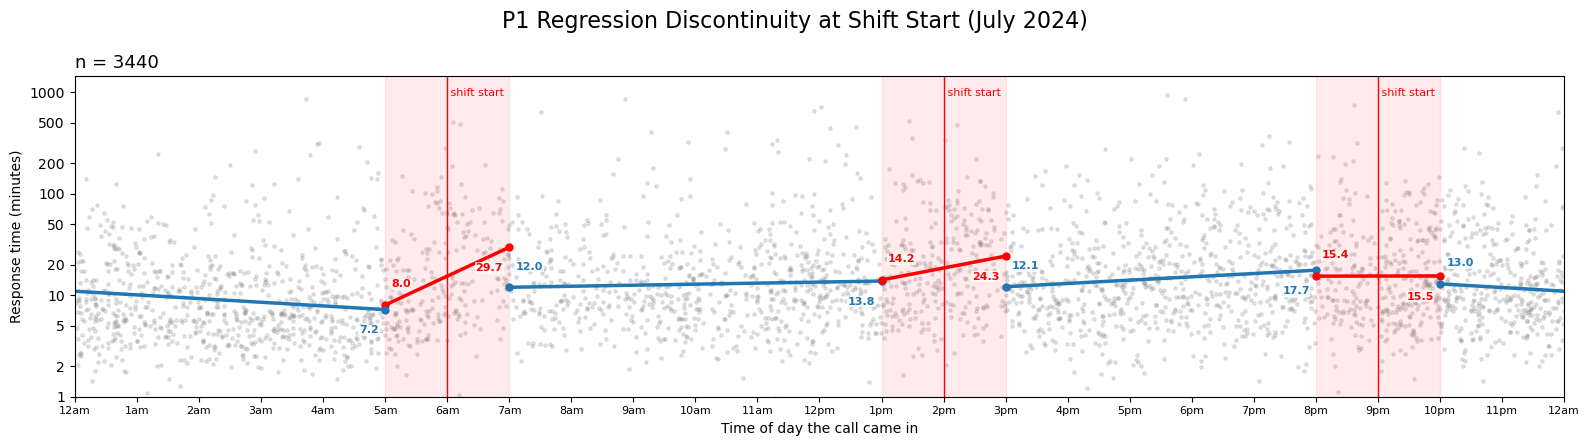

      block    hours  calls  line at start (min)  line at end (min)
shift start  5am-7am    229                  8.0               29.7
     normal  7am-1pm    727                 12.0               13.8
shift start  1pm-3pm    282                 14.2               24.3
     normal  3pm-8pm    729                 12.1               17.7
shift start 8pm-10pm    342                 15.4               15.5
     normal 10pm-5am   1131                 13.0                7.2


In [5]:
# All Areas together, with shift start blocks at 6am, 2pm and 9pm only
STARTS = [6, 14, 21]

fig, ax = plt.subplots(figsize=(16, 4.5))
calls = p1.copy()
calls["x"] = (STARTS[0] - CHANGE_HALF) + (calls["hour_of_day"] - (STARTS[0] - CHANGE_HALF)) % 24   # hours from the first block (past 24 = after midnight)
ax.scatter(calls["hour_of_day"], calls["response_min"], s=6, alpha=0.2, color="gray")

table_all = []
for start, end, kind in blocks(STARTS):
    part = calls[(calls["x"] >= start) & (calls["x"] < end)]
    slope, intercept = np.polyfit(part["x"], np.log(part["response_min"]), 1)
    # draw the line; a block that runs past midnight is drawn as two pieces (before and after 12am)
    for a, b in ([(start, 24), (24, end)] if end > 24 else [(start, end)]):
        x = np.array([a, b])
        ax.plot(x % 24 if a >= 24 else x, np.exp(intercept + slope * x), color=BLOCK_COLORS[kind], lw=2.5)
    label_ends(ax, start, end, intercept, slope, BLOCK_COLORS[kind])
    if kind == "shift start":
        ax.axvspan(start, end, color="red", alpha=0.08)
        ax.axvline(start + CHANGE_HALF, color="red", lw=1)                    # the watch start itself
        ax.text(start + CHANGE_HALF, 1100, " shift start", color="red", fontsize=8, va="top")
    table_all.append({"block": kind, "hours": f"{hour_label(start)}-{hour_label(end)}", "calls": len(part),
                      "line at start (min)": np.exp(intercept + slope * start), "line at end (min)": np.exp(intercept + slope * end)})

ax.set_yscale("log")
ax.set_yticks(Y_TICKS, labels=[str(t) for t in Y_TICKS])
ax.minorticks_off()
ax.set_ylim(1, 1440)
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25), [hour_label(h) for h in range(0, 25)], fontsize=8)   # every hour
ax.set_title(f"n = {len(calls)}", loc="left", fontsize=13)
ax.set_ylabel("Response time (minutes)")
ax.set_xlabel("Time of day the call came in")
fig.suptitle("P1 Regression Discontinuity at Shift Start (July 2024)", fontsize=16)
plt.tight_layout()
plt.show()

print(pd.DataFrame(table_all).round(1).to_string(index=False))

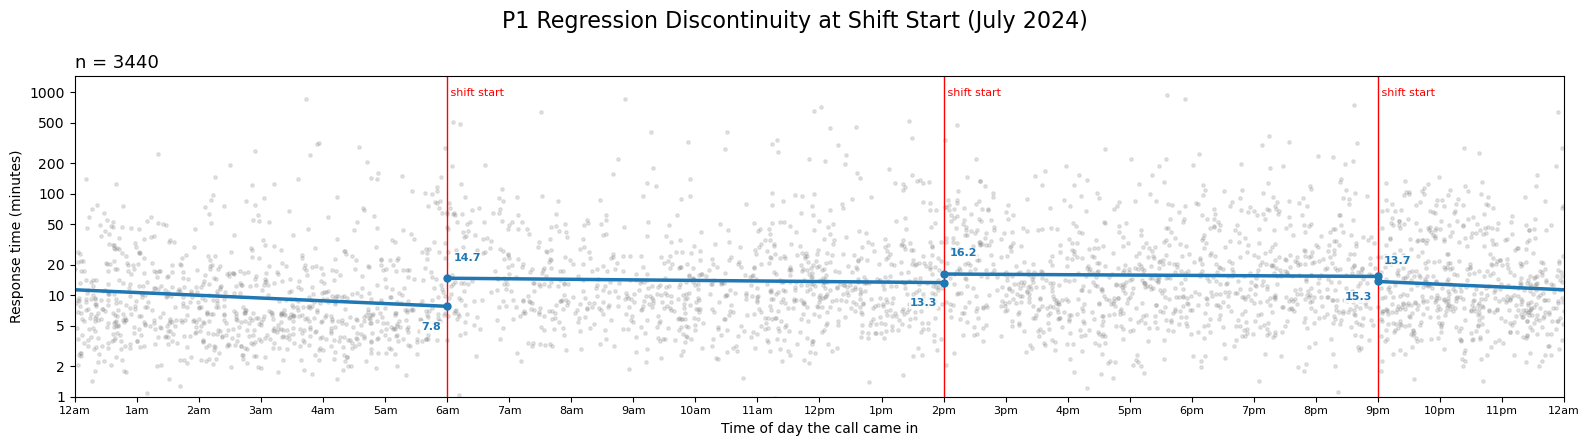

segment  calls  line at start (min)  line at end (min)
6am-2pm    972                 14.7               13.3
2pm-9pm   1001                 16.2               15.3
9pm-6am   1467                 13.7                7.8


In [6]:
# All Areas together, cutoffs at the 6am, 2pm and 9pm shift starts only: one line between each pair of cutoffs
CUTOFFS = [6, 14, 21]

fig, ax = plt.subplots(figsize=(16, 4.5))
calls = p1.copy()
calls["x"] = CUTOFFS[0] + (calls["hour_of_day"] - CUTOFFS[0]) % 24      # hours from the first cutoff (past 24 = after midnight)
ax.scatter(calls["hour_of_day"], calls["response_min"], s=6, alpha=0.2, color="gray")

segments = [(c, CUTOFFS[(i + 1) % len(CUTOFFS)] + (24 if i == len(CUTOFFS) - 1 else 0)) for i, c in enumerate(CUTOFFS)]
table_cut = []
for start, end in segments:
    part = calls[(calls["x"] >= start) & (calls["x"] < end)]
    slope, intercept = np.polyfit(part["x"], np.log(part["response_min"]), 1)
    # draw the line; a segment that runs past midnight is drawn as two pieces (before and after 12am)
    for a, b in ([(start, 24), (24, end)] if end > 24 else [(start, end)]):
        x = np.array([a, b])
        ax.plot(x % 24 if a >= 24 else x, np.exp(intercept + slope * x), color="C0", lw=2.5)
    label_ends(ax, start, end, intercept, slope, "C0")
    table_cut.append({"segment": f"{hour_label(start)}-{hour_label(end)}", "calls": len(part),
                      "line at start (min)": np.exp(intercept + slope * start), "line at end (min)": np.exp(intercept + slope * end)})
for c in CUTOFFS:
    ax.axvline(c, color="red", lw=1)
    ax.text(c, 1100, " shift start", color="red", fontsize=8, va="top")

ax.set_yscale("log")
ax.set_yticks(Y_TICKS, labels=[str(t) for t in Y_TICKS])
ax.minorticks_off()
ax.set_ylim(1, 1440)
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25), [hour_label(h) for h in range(0, 25)], fontsize=8)   # every hour
ax.set_title(f"n = {len(calls)}", loc="left", fontsize=13)
ax.set_ylabel("Response time (minutes)")
ax.set_xlabel("Time of day the call came in")
fig.suptitle("P1 Regression Discontinuity at Shift Start (July 2024)", fontsize=16)
plt.tight_layout()
plt.show()

print(pd.DataFrame(table_cut).round(1).to_string(index=False))

## P2 RDD

In [7]:
# P2 calls: same filters as the P1 calls above (911 and non-911 phone, unit needed, Area from the beat)
p2 = cad[(cad["priority"] == 2)
         & cad["call_source"].isin(["911 CALL", "DEFAULT - PHONE INIT"])
         & ~cad["disposition_code"].isin(NO_UNIT_NEEDED)].copy()
p2["response_min"] = (p2["event_number"].map(first_on_scene) - p2["event_time"]).dt.total_seconds() / 60
# keep 0 to 24 hours, same rule as for P1; this drops about 9% of timed P2 calls (P2 waits are much longer than P1)
p2 = p2[p2["response_min"].between(0, 1440)]
beat_number = pd.to_numeric(p2["beat"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
p2["area"] = pd.cut(beat_number, [0, 7, 13, 19, 25, 30, 35], labels=[1, 2, 3, 4, 5, 6]).astype("Int64")
p2 = p2.dropna(subset=["area"])
p2["hour_of_day"] = p2["event_time"].dt.hour + p2["event_time"].dt.minute / 60 + p2["event_time"].dt.second / 3600
print(len(p2), "P2 calls")

4106 P2 calls


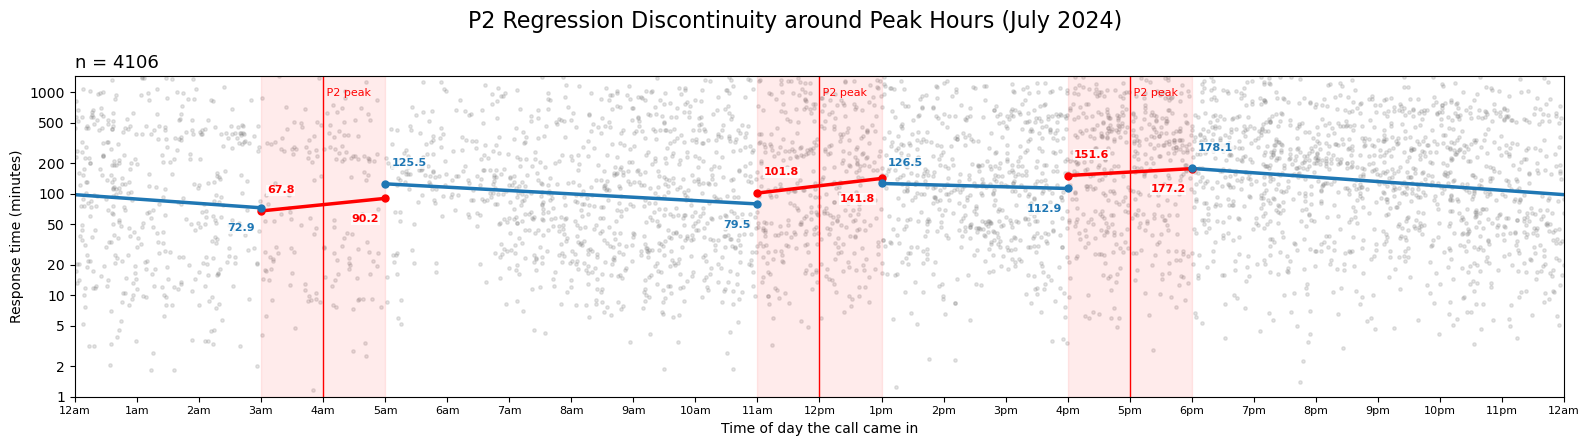

 block    hours  calls  line at start (min)  line at end (min)
  peak  3am-5am    156                 67.8               90.2
normal 5am-11am    919                125.5               79.5
  peak 11am-1pm    380                101.8              141.8
normal  1pm-4pm    574                126.5              112.9
  peak  4pm-6pm    422                151.6              177.2
normal  6pm-3am   1655                178.1               72.9


In [8]:
# P2, with blocks 1 hour either side of the 4am, 12pm and 5pm P2 peaks
STARTS = [4, 12, 17]

fig, ax = plt.subplots(figsize=(16, 4.5))
calls = p2.copy()
calls["x"] = (STARTS[0] - CHANGE_HALF) + (calls["hour_of_day"] - (STARTS[0] - CHANGE_HALF)) % 24   # hours from the first block (past 24 = after midnight)
ax.scatter(calls["hour_of_day"], calls["response_min"], s=6, alpha=0.2, color="gray")

table_p2_blocks = []
for start, end, kind in blocks(STARTS):
    part = calls[(calls["x"] >= start) & (calls["x"] < end)]
    slope, intercept = np.polyfit(part["x"], np.log(part["response_min"]), 1)
    # draw the line; a block that runs past midnight is drawn as two pieces (before and after 12am)
    for a, b in ([(start, 24), (24, end)] if end > 24 else [(start, end)]):
        x = np.array([a, b])
        ax.plot(x % 24 if a >= 24 else x, np.exp(intercept + slope * x), color=BLOCK_COLORS[kind], lw=2.5)
    label_ends(ax, start, end, intercept, slope, BLOCK_COLORS[kind])
    if kind == "shift start":
        ax.axvspan(start, end, color="red", alpha=0.08)
        ax.axvline(start + CHANGE_HALF, color="red", lw=1)                    # the peak hour itself
        ax.text(start + CHANGE_HALF, 1100, " P2 peak", color="red", fontsize=8, va="top")
    table_p2_blocks.append({"block": "peak" if kind == "shift start" else kind, "hours": f"{hour_label(start)}-{hour_label(end)}", "calls": len(part),
                      "line at start (min)": np.exp(intercept + slope * start), "line at end (min)": np.exp(intercept + slope * end)})

ax.set_yscale("log")
ax.set_yticks(Y_TICKS, labels=[str(t) for t in Y_TICKS])
ax.minorticks_off()
ax.set_ylim(1, 1440)
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25), [hour_label(h) for h in range(0, 25)], fontsize=8)   # every hour
ax.set_title(f"n = {len(calls)}", loc="left", fontsize=13)
ax.set_ylabel("Response time (minutes)")
ax.set_xlabel("Time of day the call came in")
fig.suptitle("P2 Regression Discontinuity around Peak Hours (July 2024)", fontsize=16)
plt.tight_layout()
plt.show()

print(pd.DataFrame(table_p2_blocks).round(1).to_string(index=False))

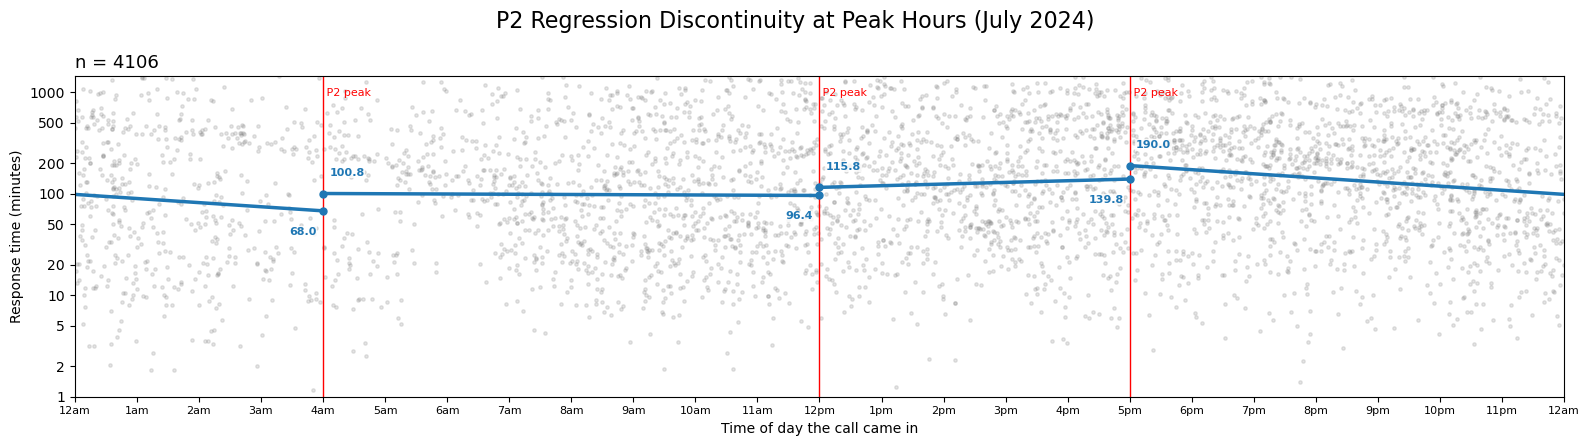

 segment  calls  line at start (min)  line at end (min)
4am-12pm   1197                100.8               96.4
12pm-5pm    975                115.8              139.8
 5pm-4am   1934                190.0               68.0


In [9]:
# P2, cutoffs at the 4am, 12pm and 5pm peaks only: one line between each pair of cutoffs
CUTOFFS = [4, 12, 17]

fig, ax = plt.subplots(figsize=(16, 4.5))
calls = p2.copy()
calls["x"] = CUTOFFS[0] + (calls["hour_of_day"] - CUTOFFS[0]) % 24      # hours from the first cutoff (past 24 = after midnight)
ax.scatter(calls["hour_of_day"], calls["response_min"], s=6, alpha=0.2, color="gray")

segments = [(c, CUTOFFS[(i + 1) % len(CUTOFFS)] + (24 if i == len(CUTOFFS) - 1 else 0)) for i, c in enumerate(CUTOFFS)]
table_p2_cut = []
for start, end in segments:
    part = calls[(calls["x"] >= start) & (calls["x"] < end)]
    slope, intercept = np.polyfit(part["x"], np.log(part["response_min"]), 1)
    # draw the line; a segment that runs past midnight is drawn as two pieces (before and after 12am)
    for a, b in ([(start, 24), (24, end)] if end > 24 else [(start, end)]):
        x = np.array([a, b])
        ax.plot(x % 24 if a >= 24 else x, np.exp(intercept + slope * x), color="C0", lw=2.5)
    label_ends(ax, start, end, intercept, slope, "C0")
    table_p2_cut.append({"segment": f"{hour_label(start)}-{hour_label(end)}", "calls": len(part),
                      "line at start (min)": np.exp(intercept + slope * start), "line at end (min)": np.exp(intercept + slope * end)})
for c in CUTOFFS:
    ax.axvline(c, color="red", lw=1)
    ax.text(c, 1100, " P2 peak", color="red", fontsize=8, va="top")

ax.set_yscale("log")
ax.set_yticks(Y_TICKS, labels=[str(t) for t in Y_TICKS])
ax.minorticks_off()
ax.set_ylim(1, 1440)
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25), [hour_label(h) for h in range(0, 25)], fontsize=8)   # every hour
ax.set_title(f"n = {len(calls)}", loc="left", fontsize=13)
ax.set_ylabel("Response time (minutes)")
ax.set_xlabel("Time of day the call came in")
fig.suptitle("P2 Regression Discontinuity at Peak Hours (July 2024)", fontsize=16)
plt.tight_layout()
plt.show()

print(pd.DataFrame(table_p2_cut).round(1).to_string(index=False))

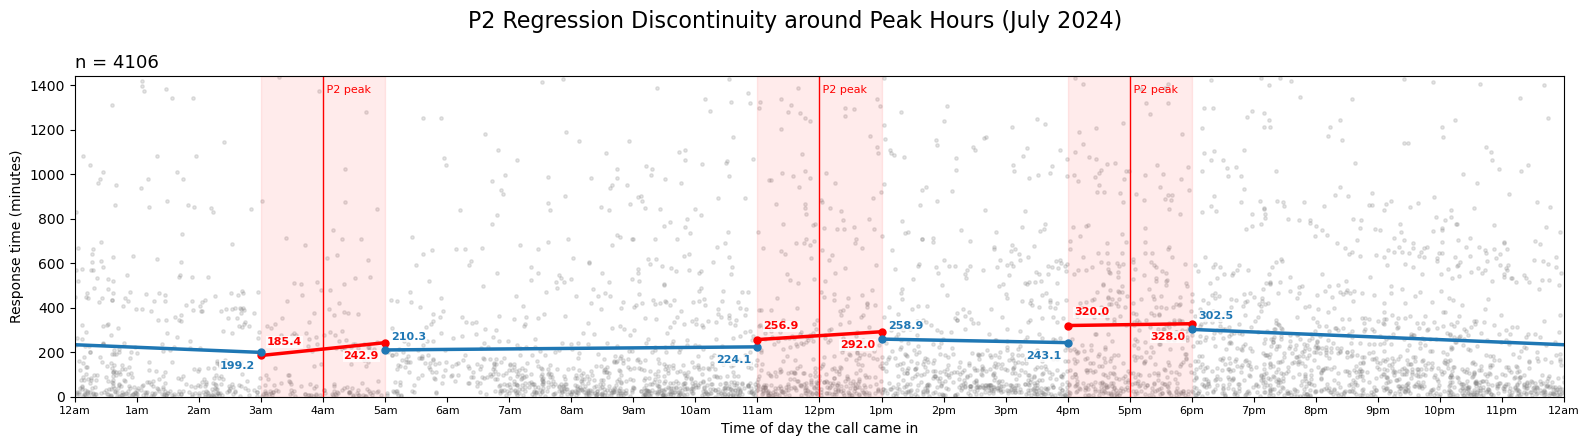

 block    hours  calls  line at start (min)  line at end (min)
  peak  3am-5am    156                185.4              242.9
normal 5am-11am    919                210.3              224.1
  peak 11am-1pm    380                256.9              292.0
normal  1pm-4pm    574                258.9              243.1
  peak  4pm-6pm    422                320.0              328.0
normal  6pm-3am   1655                302.5              199.2


In [84]:
# P2, with blocks 1 hour either side of the 4am, 12pm and 5pm P2 peaks, with no logs:
# straight lines fitted to response time in minutes, on a regular y-axis
STARTS = [4, 12, 17]

fig, ax = plt.subplots(figsize=(16, 4.5))
calls = p2.copy()
calls["x"] = (STARTS[0] - CHANGE_HALF) + (calls["hour_of_day"] - (STARTS[0] - CHANGE_HALF)) % 24   # hours from the first block (past 24 = after midnight)
ax.scatter(calls["hour_of_day"], calls["response_min"], s=6, alpha=0.2, color="gray")

table_p2_blocks_minutes = []
for start, end, kind in blocks(STARTS):
    part = calls[(calls["x"] >= start) & (calls["x"] < end)]
    slope, intercept = np.polyfit(part["x"], part["response_min"], 1)
    # draw the line; a block that runs past midnight is drawn as two pieces (before and after 12am)
    for a, b in ([(start, 24), (24, end)] if end > 24 else [(start, end)]):
        x = np.array([a, b])
        ax.plot(x % 24 if a >= 24 else x, intercept + slope * x, color=BLOCK_COLORS[kind], lw=2.5)
    # dot and value at both ends of the line: start value above right, end value below left
    for x_at, dx, dy, align in [(start, 0.1, 60, "left"), (end, -0.1, -60, "right")]:
        y = intercept + slope * x_at
        x_shown = x_at - 24 if x_at > 24 else x_at
        ax.plot(x_shown, y, "o", color=BLOCK_COLORS[kind], ms=5, zorder=3)
        ax.text(x_shown + dx, y + dy, f"{y:.1f}", color=BLOCK_COLORS[kind], fontsize=8, fontweight="bold", ha=align, va="center",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.5), zorder=4)
    if kind == "shift start":
        ax.axvspan(start, end, color="red", alpha=0.08)
        ax.axvline(start + CHANGE_HALF, color="red", lw=1)                    # the peak hour itself
        ax.text(start + CHANGE_HALF, 1400, " P2 peak", color="red", fontsize=8, va="top")
    table_p2_blocks_minutes.append({"block": "peak" if kind == "shift start" else kind, "hours": f"{hour_label(start)}-{hour_label(end)}", "calls": len(part),
                      "line at start (min)": intercept + slope * start, "line at end (min)": intercept + slope * end})

ax.set_ylim(0, 1440)
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25), [hour_label(h) for h in range(0, 25)], fontsize=8)   # every hour
ax.set_title(f"n = {len(calls)}", loc="left", fontsize=13)
ax.set_ylabel("Response time (minutes)")
ax.set_xlabel("Time of day the call came in")
fig.suptitle("P2 Regression Discontinuity around Peak Hours (July 2024)", fontsize=16)
plt.tight_layout()
plt.show()

print(pd.DataFrame(table_p2_blocks_minutes).round(1).to_string(index=False))

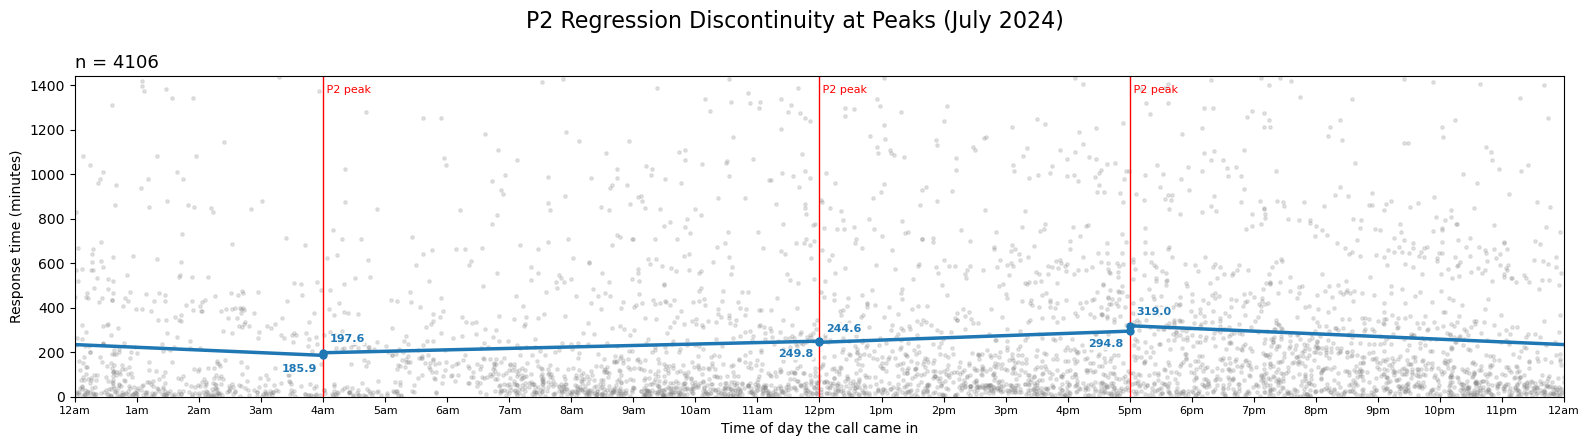

 segment  calls  line at start (min)  line at end (min)
4am-12pm   1197                197.6              249.8
12pm-5pm    975                244.6              294.8
 5pm-4am   1934                319.0              185.9


In [11]:
# P2, cutoffs at 4am, 12pm and 5pm, with no logs: straight lines fitted to response time in minutes, on a regular y-axis
fig, ax = plt.subplots(figsize=(16, 4.5))
calls = p2.copy()
calls["x"] = CUTOFFS[0] + (calls["hour_of_day"] - CUTOFFS[0]) % 24      # hours from the first cutoff (past 24 = after midnight)
ax.scatter(calls["hour_of_day"], calls["response_min"], s=6, alpha=0.2, color="gray")

segments = [(c, CUTOFFS[(i + 1) % len(CUTOFFS)] + (24 if i == len(CUTOFFS) - 1 else 0)) for i, c in enumerate(CUTOFFS)]
table_p2_cut_minutes = []
for start, end in segments:
    part = calls[(calls["x"] >= start) & (calls["x"] < end)]
    slope, intercept = np.polyfit(part["x"], part["response_min"], 1)
    # draw the line; a segment that runs past midnight is drawn as two pieces (before and after 12am)
    for a, b in ([(start, 24), (24, end)] if end > 24 else [(start, end)]):
        x = np.array([a, b])
        ax.plot(x % 24 if a >= 24 else x, intercept + slope * x, color="C0", lw=2.5)
    # dot and value at both ends of the line: start value above right, end value below left
    for x_at, dx, dy, align in [(start, 0.1, 60, "left"), (end, -0.1, -60, "right")]:
        y = intercept + slope * x_at
        x_shown = x_at - 24 if x_at > 24 else x_at
        ax.plot(x_shown, y, "o", color="C0", ms=5, zorder=3)
        ax.text(x_shown + dx, y + dy, f"{y:.1f}", color="C0", fontsize=8, fontweight="bold", ha=align, va="center",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.5), zorder=4)
    table_p2_cut_minutes.append({"segment": f"{hour_label(start)}-{hour_label(end)}", "calls": len(part),
                                 "line at start (min)": intercept + slope * start, "line at end (min)": intercept + slope * end})
for c in CUTOFFS:
    ax.axvline(c, color="red", lw=1)
    ax.text(c, 1400, " P2 peak", color="red", fontsize=8, va="top")

ax.set_ylim(0, 1440)
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25), [hour_label(h) for h in range(0, 25)], fontsize=8)   # every hour
ax.set_title(f"n = {len(calls)}", loc="left", fontsize=13)
ax.set_ylabel("Response time (minutes)")
ax.set_xlabel("Time of day the call came in")
fig.suptitle("P2 Regression Discontinuity at Peaks (July 2024)", fontsize=16)
plt.tight_layout()
plt.show()

print(pd.DataFrame(table_p2_cut_minutes).round(1).to_string(index=False))